In [2]:
pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 14.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=6029a6d5eae4ca63b5e94fda50b5648323e3a2b88d73322a9be141ab10806a39
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


In [3]:
"""
Builds the train/test dataset for the account type classifier.

What it does:
    Downloads the chart-of-accounts (COA) CSVs from every Odoo l10n_XX
    country module (Odoo branch 17.0) and turns them into one cleaned dataset.

Input:
    None. Data is fetched from github.com/odoo/odoo, so internet and git are
    required. A metadata-only clone is stored in ./odoo_repo/.

Cleaning steps:
    1. Keep only COA files that have id, name and account_type columns.
    2. Drop duplicate (account_name, account_type) rows.
    3. Drop account names with non-English characters.
    4. Drop account types with 100 rows or fewer.

Output (in ./data/):
    train.csv  - 80% of rows
    test.csv   - 20% of rows (stratified by account_type, random_state=42)
    Columns: account_id, account_name, account_type, country, account_name_original

Requirements: pandas, scikit-learn, langdetect, git.
Run on Google Colab, then download the data/ folder for training.
"""

import unicodedata
import os, subprocess, io, re, sys
import pandas as pd
from sklearn.model_selection import train_test_split
from langdetect import detect_langs

REPO_DIR = "odoo_repo"


def git(*args):
    return subprocess.run(
        ["git", "-C", REPO_DIR] + list(args),
        capture_output=True,
        text=True,
        encoding="utf-8",   # git outputs UTF-8; Windows would otherwise default to cp1252
        errors="replace"    # a bad byte becomes "?" instead of crashing the reader thread
    )


def is_english(text):
    if not text or str(text).strip() == "":
        return False

    for ch in str(text):
        if 32 <= ord(ch) <= 126:
            continue                          # normal printable ASCII: always allowed

        # Ask Python what kind of character this is. It returns a 2-letter code:
        # the first letter is the group (L = letter, M = accent mark, N = number,
        # P = punctuation, S = symbol, Z = space, C = invisible/control),
        # the second letter is the subtype (e.g. "Pd" = dash, "Lu" = uppercase letter).
        cat = unicodedata.category(ch)
        if cat[0] in ("L", "M") or cat == "Nd":
            return False                      # real foreign text: reject the name

        # Anything else (dashes, fancy quotes, symbols, odd spaces, invisible characters)
        # is not a foreign word, so we let it pass and check the next character.
    return True


# Remember every translation so a repeated name is only sent to Google once
"""
translation_cache = {}

def translate_account_name(name, retries=5):
    # Already translated earlier? Return it without calling Google
    if name in translation_cache:
        return translation_cache[name]

    for attempt in range(retries):
        try:
            result = GoogleTranslator(source="auto", target="en").translate(name)
            result = result or name          # if Google returns nothing, keep the original
            translation_cache[name] = result
            time.sleep(0.3)                  # pause after each call: ~3 requests/sec, under the 5/sec limit
            return result
        except Exception:
            # Rate-limited: wait longer after each failure (2s, 4s, 8s, 16s, 32s)
            time.sleep(2 ** (attempt + 1))

    # All retries failed: keep the original name and report it
    print(f"Translation failed for '{name}'")
    translation_cache[name] = name
    return name
"""

if __name__ == "__main__":

    os.makedirs("data", exist_ok=True)

    # ---------------------------------------------------------
    # 1. Shallow, blob-less clone — metadata only, no bulk downloads.
    #    Also sidesteps the old bug: blob URLs return HTML, not CSV.
    # ---------------------------------------------------------
    if not os.path.exists(REPO_DIR):
        try:
            subprocess.run(
                ["git", "clone", "--depth", "1", "--filter=blob:none", "--no-checkout",
                 "-b", "17.0", "https://github.com/odoo/odoo.git", REPO_DIR],
                check=True
            )
        except FileNotFoundError:
            sys.exit("Error: 'git' is not installed or not on PATH.")
        except subprocess.CalledProcessError as e:
            sys.exit(
                f"Error: git clone failed (exit code {e.returncode}). "
                "Check your network connection and try again."
            )

    # ---------------------------------------------------------
    # 2. Discover ALL l10n_XX modules and locate their
    #    Chart-of-Accounts CSV files regardless of folder layout.
    # ---------------------------------------------------------

    result = git("ls-tree", "-d", "--name-only", "HEAD:addons")
    if result.returncode != 0:
        sys.exit(
            f"Error: could not list addons/ in the Odoo repo.\n"
            f"git stderr: {result.stderr.strip()}"
        )

    folders = result.stdout.splitlines()

    two_letter_codes = sorted(
        m.group(1)
        for f in folders
        if (m := re.match(r"^l10n_([a-z]{2})$", f))
    )

    print(f"Total l10n_XX modules: {len(two_letter_codes)}")

    # ---------------------------------------------------------
    # 3. Search each localization module recursively for CSVs
    #    that appear to contain Chart-of-Accounts data.
    # ---------------------------------------------------------

    country_files = {}
    no_coa = []

    for code in two_letter_codes:

        module = f"addons/l10n_{code}"

        # Get every file in this localization module
        result = git("ls-tree", "-r", "--name-only", f"HEAD:{module}")

        if result.returncode != 0:
            no_coa.append(code)
            continue

        files = result.stdout.splitlines()

        csv_candidates = [
            fname for fname in files
            if fname.lower().endswith(".csv")
            and (
                "account" in os.path.basename(fname).lower()
                or "coa" in os.path.basename(fname).lower()
            )
        ]

        found = False

        for relative_path in csv_candidates:

            full_path = f"{module}/{relative_path}"

            result = git("show", f"HEAD:{full_path}")

            if result.returncode != 0:
                continue

            try:
                df = pd.read_csv(io.StringIO(result.stdout), nrows=5)
            except Exception:
                continue

            # Accept files containing the basic COA fields
            columns_lower = {c.lower(): c for c in df.columns}

            has_name = "name" in columns_lower
            has_type = "account_type" in columns_lower

            if has_name and has_type:
                country_files[code] = relative_path
                found = True
                break

        if not found:
            no_coa.append(code)

    # ---------------------------------------------------------
    # 4. Report exactly what was discovered
    # ---------------------------------------------------------

    print(f"\nCountries with usable COA CSV: {len(country_files)}")
    print(f"Countries without usable COA CSV: {len(no_coa)}")

    """
    print("\nCOA files found:")
    for code, path in country_files.items():
        print(f"{code}: {path}")
    """

    print("\nNo usable COA CSV found:")
    print(no_coa)

    # ---------------------------------------------------------
    # 5. Load + validate each candidate (required columns + usable rows)
    # ---------------------------------------------------------
    REQUIRED_COLS = ["id", "name", "account_type"]

    country_dfs = {}

    for code, relative_path in country_files.items():

        path = f"addons/l10n_{code}/{relative_path}"

        result = git("show", f"HEAD:{path}")

        if result.returncode != 0:
            print(f"{code}: FAILED to fetch {relative_path}")
            continue

        try:
            df = pd.read_csv(io.StringIO(result.stdout), on_bad_lines="skip")
        except Exception as e:
            print(f"{code}: FAILED to parse ({e})")
            continue

        # Handle column names
        if not all(c in df.columns for c in ["id", "name", "account_type"]):
            print(f"{code}: missing required columns")
            continue

        df = df[["id", "name", "account_type"]].rename(
            columns={
                "id": "account_id",
                "name": "account_name"
            }
        )

        df = df.dropna(subset=["account_name", "account_type"])

        if df.empty:
            continue

        df["country"] = code
        country_dfs[code] = df

    if not country_dfs:
        sys.exit("Error: no usable country data found. Cannot build dataset.")

    print(f"\nUsing {len(country_dfs)} countries: {list(country_dfs.keys())}")

    combined_df = pd.concat(country_dfs.values(), ignore_index=True)
    print(f"Combined (pre-cutoff): {len(combined_df)} rows")

    # duplicate data remove
    before = len(combined_df)
    combined_df = combined_df.drop_duplicates(subset=["account_name", "account_type"]).reset_index(drop=True)
    print(f"\nDropped {before - len(combined_df)} duplicate rows from dataset.")

    print("\nCounts per class after original duplicate removal:")
    print(combined_df["account_type"].value_counts().sort_index())

    # run right after building combined_df from Odoo
    combined_df["account_name_original"] = combined_df["account_name"]
    non_en_mask = combined_df["account_name"].astype(str).apply(lambda x: not is_english(x))

    # TEMPORARY CHECK: show up to 40 random flagged names with the language langdetect guessed
    flagged = combined_df[non_en_mask]["account_name"].astype(str)
    sample_size = min(40, len(flagged))
    if sample_size > 0:
        for name in flagged.sample(sample_size, random_state=1):
            print(f"{detect_langs(name)[0]}  ->  {name}")   # e.g. "nl:0.99  ->  Main Safe"

    # Keep only the rows NOT flagged (~ flips the mask: True becomes False and vice versa)
    print(f"Removing {non_en_mask.sum()} non-English account names.")
    combined_df = combined_df[~non_en_mask].reset_index(drop=True)
    print(f"Rows remaining: {len(combined_df)}")

    # remove classes with less than or equal to 100 instances only
    # Count how many rows each account_type has
    class_counts = combined_df["account_type"].value_counts()
    print("Removing classes:", list(class_counts[class_counts <= 100].index))

    # Class names that have MORE than 100 rows: these are the ones we keep
    keep_classes = class_counts[class_counts > 100].index
    combined_df = combined_df[combined_df["account_type"].isin(keep_classes)].reset_index(drop=True)

    class_counts = combined_df["account_type"].value_counts()
    tiny_classes = class_counts[class_counts < 2].index
    if len(tiny_classes) > 0:
        print(f"Dropping classes with <2 rows (cannot stratify): {list(tiny_classes)}")
        combined_df = combined_df[~combined_df["account_type"].isin(tiny_classes)].reset_index(drop=True)

    # Check: the remaining classes and their counts
    print(f"Rows remaining: {len(combined_df)}")
    print(combined_df["account_type"].value_counts())

    if combined_df.empty:
        sys.exit("Error: no data remaining after filtering. Cannot split.")

    # Stratified split: every account_type appears in both train and test
    # in roughly the same proportion as in the full dataset.
    train_df, test_df = train_test_split(
        combined_df,
        test_size=0.2,                         # 20% of rows go to test
        stratify=combined_df["account_type"],  # keep class proportions equal in both splits
        random_state=42                        # makes the split reproducible
    )

    # Check: class proportions should be nearly identical in both splits
    print("Train class share:")
    print(train_df["account_type"].value_counts(normalize=True).sort_index())
    print("\nTest class share:")
    print(test_df["account_type"].value_counts(normalize=True).sort_index())

    os.makedirs("data", exist_ok=True)
    train_df.to_csv("data/train.csv", index=False)
    test_df.to_csv("data/test.csv", index=False)

    print(f"\nSaved {len(train_df)} train rows and {len(test_df)} test rows to data/.")


Total l10n_XX modules: 104

Countries with usable COA CSV: 85
Countries without usable COA CSV: 19

No usable COA CSV found:
['bf', 'bj', 'cd', 'cf', 'cg', 'ci', 'cm', 'ga', 'gn', 'gq', 'gw', 'km', 'ml', 'ne', 'ng', 'sn', 'td', 'tg', 'us']

Using 85 countries: ['ae', 'ar', 'at', 'au', 'bd', 'be', 'bg', 'bh', 'bo', 'br', 'ca', 'ch', 'cl', 'cn', 'co', 'cr', 'cy', 'cz', 'de', 'dk', 'do', 'dz', 'ec', 'ee', 'eg', 'es', 'et', 'fi', 'fr', 'gr', 'gt', 'hk', 'hn', 'hr', 'hu', 'id', 'ie', 'il', 'in', 'iq', 'it', 'jo', 'jp', 'ke', 'kw', 'kz', 'lt', 'lu', 'lv', 'ma', 'mn', 'mr', 'mt', 'mx', 'my', 'mz', 'nl', 'no', 'nz', 'pa', 'pe', 'ph', 'pk', 'pl', 'pt', 'qa', 'ro', 'rs', 'rw', 'sa', 'se', 'sg', 'si', 'sk', 'th', 'tn', 'tr', 'tw', 'ua', 'ug', 'uk', 'uy', 've', 'vn', 'za']
Combined (pre-cutoff): 24215 rows

Dropped 4074 duplicate rows from dataset.

Counts per class after original duplicate removal:
account_type
asset_cash                276
asset_current            3032
asset_fixed              1

Using device: cuda
Classes: ['asset_cash', 'asset_current', 'asset_fixed', 'asset_non_current', 'asset_prepayments', 'asset_receivable', 'equity', 'expense', 'expense_depreciation', 'expense_direct_cost', 'income', 'income_other', 'liability_current', 'liability_non_current', 'liability_payable', 'off_balance']


config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch  1 | loss: 1.7306 | train_acc: 0.617 | test_acc: 0.575
Epoch  2 | loss: 1.2418 | train_acc: 0.683 | test_acc: 0.612
Epoch  3 | loss: 1.0424 | train_acc: 0.743 | test_acc: 0.646
Epoch  4 | loss: 0.9024 | train_acc: 0.789 | test_acc: 0.659
Epoch  5 | loss: 0.7951 | train_acc: 0.824 | test_acc: 0.664
Epoch  6 | loss: 0.7034 | train_acc: 0.852 | test_acc: 0.668
Epoch  7 | loss: 0.6227 | train_acc: 0.868 | test_acc: 0.664
Epoch  8 | loss: 0.5611 | train_acc: 0.891 | test_acc: 0.670
Epoch  9 | loss: 0.5083 | train_acc: 0.902 | test_acc: 0.672
Epoch 10 | loss: 0.4619 | train_acc: 0.904 | test_acc: 0.665
Epoch 11 | loss: 0.4243 | train_acc: 0.914 | test_acc: 0.669
Epoch 12 | loss: 0.3841 | train_acc: 0.925 | test_acc: 0.671
Early stopping at epoch 12 (best test_acc: 0.672)
Restored best weights (test_acc: 0.672)
Training curve saved to output/training_curve.png


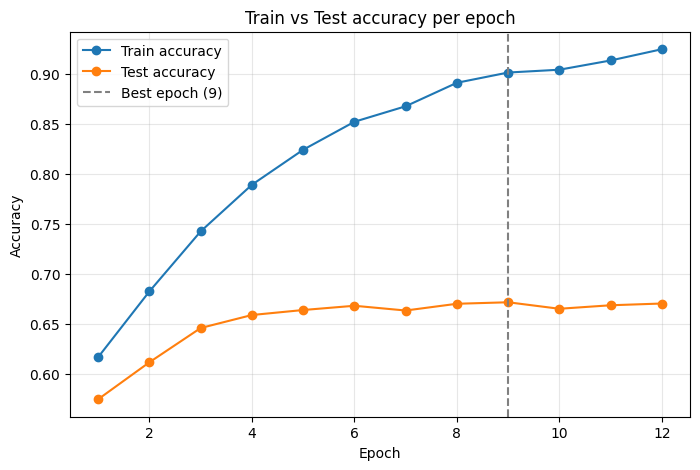

Evaluation Duration: 3.27 seconds

Final test accuracy: 0.672

                       precision    recall  f1-score   support

           asset_cash       0.50      0.49      0.50        55
        asset_current       0.61      0.66      0.63       602
          asset_fixed       0.70      0.67      0.69       276
    asset_non_current       0.61      0.61      0.61       310
    asset_prepayments       0.45      0.58      0.51        26
     asset_receivable       0.74      0.56      0.64       107
               equity       0.77      0.72      0.74       197
              expense       0.78      0.78      0.78      1008
 expense_depreciation       0.69      0.61      0.65        75
  expense_direct_cost       0.51      0.40      0.44        81
               income       0.64      0.67      0.65       311
         income_other       0.58      0.47      0.52       171
    liability_current       0.64      0.72      0.68       502
liability_non_current       0.65      0.63      0.64  

In [4]:
"""
Fine-tunes MiniLM to classify an account name into an account type.

What it does:
    Trains all-MiniLM-L6-v2 (mean pooling + dropout + linear layer) to predict
    account_type from account_name. Training stops early if test accuracy does
    not improve for 3 epochs, and the best epoch's weights are restored before
    the final report and saving.

Input (from the data-building script):
    data/train.csv, data/test.csv
    Required columns: account_name, account_type

Output:
    account_type_classifier/   (used by the inference pipeline)
        model_state_dict.pt    - best weights
        tokenizer files        - saved tokenizer
        label_classes.json     - class names, in label order
        config.json            - base model, hidden size, num_classes, max_len
    experiment_log.xlsx        - one row appended per run (settings, accuracy,
                                 macro/weighted F1, per-class F1 and support)
    Also prints the per-class classification report.

Settings (top of file): NUM_FROZEN_LAYERS, DROPOUT, EPOCHS.
    NUM_FROZEN_LAYERS is only logged for now, because the freezing code is
    commented out.

Note: the test set is used to pick the best epoch

Requirements: torch, transformers, scikit-learn, pandas, numpy, openpyxl,
    matplotlib.                                        # Fix 12: added matplotlib
    A GPU is recommended, but it also runs on CPU.
"""

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np
import random
import time
import os
import sys
import json
from datetime import datetime
import matplotlib
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# Config for this run — change these between experiments
# ---------------------------------------------------------
NUM_FROZEN_LAYERS = 0
DROPOUT = 0.1
EPOCHS = 20
MAX_LEN = 32              # Fix 13: single constant for tokenizer max length

# ---------------------------------------------------------
# Reproducibility + device
# ---------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---------------------------------------------------------
# Early stopping setup
# ---------------------------------------------------------
PATIENCE = 3              # how many epochs to wait for improvement before stopping
best_test_acc = 0.0       # best accuracy seen so far (starts at 0 so epoch 1 always counts as an improvement)
epochs_no_improve = 0     # counter: epochs in a row with no improvement
best_state = None         # will hold a copy of the weights from the best epoch

# ---------------------------------------------------------
# Dataset — now uses account_type_label (int) instead of raw string labels
# ---------------------------------------------------------
class AccountNameDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=MAX_LEN):   # Fix 13: use constant
        self.names = df["account_name"].tolist()
        self.labels = df["account_type_label"].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        # Fix 9: cast to str to guard against NaN / non-string values
        name = str(self.names[idx])
        enc = self.tokenizer(
            name,
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt",
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long),
        }

# ---------------------------------------------------------
# Model: MiniLM encoder + classification head (mean pooling)
# ---------------------------------------------------------
class AccountTypeClassifier(nn.Module):
    # Fix 8: hidden_size is now read dynamically; kept as param for flexibility
    def __init__(self, base_model, hidden_size=None, num_classes=5):
        super().__init__()
        self.base_model = base_model
        # If no hidden_size passed, read it from the base model config
        if hidden_size is None:
            hidden_size = base_model.config.hidden_size
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.base_model(input_ids=input_ids, attention_mask=attention_mask)
        pooled = mean_pool(outputs.last_hidden_state, attention_mask)
        pooled = self.dropout(pooled)
        return self.classifier(pooled)

def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    summed = torch.sum(last_hidden_state * mask, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

# ---------------------------------------------------------
# Evaluation function
# ---------------------------------------------------------

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            logits = model(input_ids, attention_mask)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    # Fix 3: guard against empty loader (total == 0)
    if total == 0:
        return 0.0, [], []
    return correct / total, all_preds, all_labels

# ---------------------------------------------------------
# Log this run's config + metrics to a persistent Excel file
# ---------------------------------------------------------

def log_run_to_excel(
    frozen_layers,
    dropout,
    final_test_acc,
    test_preds,
    test_labels,
    type_encoder,
    excel_path="output/experiment_log.xlsx",
    extra_info=None,
):
    # Create the folder part of the path ("output") if it doesn't exist yet.
    # exist_ok=True means no error if the folder is already there.
    os.makedirs(os.path.dirname(excel_path), exist_ok=True)

    report_dict = classification_report(
        test_labels, test_preds,
        labels=list(range(len(type_encoder.classes_))),
        target_names=type_encoder.classes_,
        zero_division=0,
        output_dict=True,
    )

    row = {
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "frozen_layers": frozen_layers,
        "dropout": dropout,
        "test_accuracy": final_test_acc,
        "macro_precision": report_dict["macro avg"]["precision"],
        "macro_recall": report_dict["macro avg"]["recall"],
        "macro_f1": report_dict["macro avg"]["f1-score"],
        "weighted_precision": report_dict["weighted avg"]["precision"],
        "weighted_recall": report_dict["weighted avg"]["recall"],
        "weighted_f1": report_dict["weighted avg"]["f1-score"],
    }

    if extra_info:
        row.update(extra_info)

    # per-class F1 + support, so you can see exactly which classes
    # improve/degrade as you sweep frozen_layers / dropout
    for cls in type_encoder.classes_:
        row[f"f1_{cls}"] = report_dict[cls]["f1-score"]
        row[f"support_{cls}"] = report_dict[cls]["support"]

    new_row_df = pd.DataFrame([row])

    if os.path.exists(excel_path):
        existing_df = pd.read_excel(excel_path)
        combined_df = pd.concat([existing_df, new_row_df], ignore_index=True)
    else:
        combined_df = new_row_df

    # Fix 7: handle PermissionError (file open in Excel on Windows)
    try:
        combined_df.to_excel(excel_path, index=False)
        print(f"Logged run to {excel_path} (frozen_layers={frozen_layers}, dropout={dropout})")
    except PermissionError:
        fallback = excel_path.replace(".xlsx", f"_{int(time.time())}.xlsx")
        combined_df.to_excel(fallback, index=False)
        print(f"Warning: {excel_path} is locked. Saved to {fallback} instead.")
    return combined_df


# Fix 11: all pipeline logic inside main guard
if __name__ == "__main__":

    # ---------------------------------------------------------
    # Load the combined train/test CSVs saved from notebook 1
    # ---------------------------------------------------------

    # Fix 1: guard against missing data files
    for required_file in ("data/train.csv", "data/test.csv"):
        if not os.path.exists(required_file):
            sys.exit(
                f"Error: '{required_file}' not found. "
                "Run dataset.py first to generate the training data."
            )

    try:
        train_df = pd.read_csv("data/train.csv")
        test_df = pd.read_csv("data/test.csv")
    except Exception as e:
        sys.exit(f"Error: failed to read data files: {e}")

    # Fix 10: validate required columns and drop NaN before encoding
    for label, df in [("train.csv", train_df), ("test.csv", test_df)]:
        for col in ("account_name", "account_type"):
            if col not in df.columns:
                sys.exit(f"Error: '{col}' column missing from {label}.")

    train_df = train_df.dropna(subset=["account_name", "account_type"])
    test_df = test_df.dropna(subset=["account_name", "account_type"])

    if train_df.empty or test_df.empty:
        sys.exit("Error: train or test data is empty after dropping NaN rows.")

    type_encoder = LabelEncoder().fit(pd.concat([train_df["account_type"], test_df["account_type"]]))
    train_df["account_type_label"] = type_encoder.transform(train_df["account_type"])
    test_df["account_type_label"] = type_encoder.transform(test_df["account_type"])

    num_classes = len(type_encoder.classes_)
    print("Classes:", list(type_encoder.classes_))

    # ---------------------------------------------------------
    # Tokenizer + base model
    # ---------------------------------------------------------
    # model_name = "sentence-transformers/all-MiniLM-L6-v2" # 68% acc, 22M parameters
    model_name = "BAAI/bge-small-en-v1.5" # 89% acc, 33.4M params

    # Fix 2: handle network / model download failures
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        base_model = AutoModel.from_pretrained(model_name).to(device)
    except OSError as e:
        sys.exit(
            f"Error: failed to load model '{model_name}'.\n"
            f"Check your internet connection or that the model name is correct.\n"
            f"Details: {e}"
        )
    except Exception as e:
        sys.exit(f"Error: unexpected failure loading model '{model_name}': {e}")

    # Fix 8: read hidden_size from the model config dynamically
    hidden_size = base_model.config.hidden_size

    """
    # Freeze embeddings
    for param in base_model.embeddings.parameters():
        param.requires_grad = False

    # Freeze first of MiniLM's 6 encoder layers
    for layer in base_model.encoder.layer[:(NUM_FROZEN_LAYERS-1)]:
        for param in layer.parameters():
            param.requires_grad = False
    """

    # ---------------------------------------------------------
    # Training
    # ---------------------------------------------------------
    train_dataset = AccountNameDataset(train_df, tokenizer)
    test_dataset = AccountNameDataset(test_df, tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=16)

    model = AccountTypeClassifier(base_model, hidden_size=hidden_size, num_classes=num_classes).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    loss_fn = nn.CrossEntropyLoss()

    train_acc_history = []   # will hold train accuracy of each epoch
    test_acc_history = []    # will hold test accuracy of each epoch

    # Fix 5: wrap training loop to handle CUDA OOM gracefully
    try:
        for epoch in range(1, EPOCHS + 1):
            model.train()
            total_loss = 0
            for batch in train_loader:
                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["label"].to(device)

                optimizer.zero_grad()
                logits = model(input_ids, attention_mask)
                loss = loss_fn(logits, labels)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()

            train_acc, _, _ = evaluate(model, train_loader)
            test_acc, _, _ = evaluate(model, test_loader)
            train_acc_history.append(train_acc)               # save this epoch's train accuracy
            test_acc_history.append(test_acc)

            # Fix 4: print epoch summary BEFORE early stopping check
            print(f"Epoch {epoch:2d} | loss: {total_loss/len(train_loader):.4f} | train_acc: {train_acc:.3f} | test_acc: {test_acc:.3f}")

            # --- Early stopping check (runs once per epoch, after evaluation) ---
            if test_acc > best_test_acc:
                best_test_acc = test_acc          # new best score
                epochs_no_improve = 0             # improvement happened, so reset the counter
                # copy the weights to CPU memory; clone() makes a real copy, not a reference
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                epochs_no_improve += 1            # no improvement this epoch
                if epochs_no_improve >= PATIENCE:
                    print(f"Early stopping at epoch {epoch} (best test_acc: {best_test_acc:.3f})")
                    break                         # exit the epoch loop

    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            print(f"\nError: CUDA out of memory at epoch {epoch}.")
            if best_state is not None:
                print("Saving best checkpoint so far before exiting...")
                save_dir = "account_type_classifier"
                os.makedirs(save_dir, exist_ok=True)
                torch.save(best_state, os.path.join(save_dir, "model_state_dict_oom_recovery.pt"))
                print(f"Recovery checkpoint saved to {save_dir}/model_state_dict_oom_recovery.pt")
            sys.exit("Reduce batch size or model size and try again.")
        else:
            raise  # re-raise non-OOM RuntimeErrors

    # ---------------------------------------------------------
    # Restore the best weights before final evaluation and saving
    # ---------------------------------------------------------
    if best_state is not None:                 # safety check: only restore if a best epoch was recorded
        model.load_state_dict(best_state)      # copies the best epoch's weights back into the model
        print(f"Restored best weights (test_acc: {best_test_acc:.3f})")
    # Re-measure train accuracy on the restored best weights, so the log matches the saved model
    best_train_acc, _, _ = evaluate(model, train_loader)   # evaluate() returns (accuracy, preds, labels); we only need accuracy

    # plotting
    # x-axis: epoch numbers 1, 2, 3, ... for however many epochs actually ran
    # (fewer than EPOCHS if early stopping triggered)
    epochs_ran = range(1, len(train_acc_history) + 1)

    # Epoch with the highest test accuracy (argmax gives a 0-based index, so +1)
    best_epoch = int(np.argmax(test_acc_history)) + 1

    # Fix 6: use Agg backend if no display is available, save plot to file
    try:
        plt.figure(figsize=(8, 5))                                   # width x height in inches
        plt.plot(epochs_ran, train_acc_history, marker="o", label="Train accuracy")   # blue line: train
        plt.plot(epochs_ran, test_acc_history, marker="o", label="Test accuracy")     # orange line: test
        plt.axvline(best_epoch, linestyle="--", color="gray", label=f"Best epoch ({best_epoch})")  # dashed line at the best epoch
        plt.xlabel("Epoch")                                          # label under the x-axis
        plt.ylabel("Accuracy")                                       # label beside the y-axis
        plt.title("Train vs Test accuracy per epoch")                # plot title
        plt.legend()                                                 # shows which line is which
        plt.grid(alpha=0.3)                                          # faint grid to make values easier to read
        os.makedirs("output", exist_ok=True)
        plt.savefig("output/training_curve.png", dpi=150, bbox_inches="tight")
        print("Training curve saved to output/training_curve.png")
        plt.show()                                                   # displays the plot below the cell
    except Exception:
        print("Warning: could not display plot (headless environment?). Curve saved to output/training_curve.png.")

    # ---------------------------------------------------------
    # Final test report (per-class — worth checking given class imbalance)
    # ---------------------------------------------------------

    start_time = time.time()

    final_test_acc, test_preds, test_labels = evaluate(model, test_loader)

    end_time = time.time()
    duration = end_time - start_time

    print(f"Evaluation Duration: {duration:.2f} seconds")
    print(f"\nFinal test accuracy: {final_test_acc:.3f}\n")
    print(classification_report(
        test_labels, test_preds,
        labels=list(range(num_classes)),
        target_names=type_encoder.classes_,
        zero_division=0,
    ))

    log_run_to_excel(
        frozen_layers=NUM_FROZEN_LAYERS,
        dropout=DROPOUT,
        final_test_acc=final_test_acc,
        test_preds=test_preds,
        test_labels=test_labels,
        type_encoder=type_encoder,
        extra_info={"epochs": EPOCHS, "lr": 2e-5, "train_acc_final": best_train_acc},
    )

    # ---------------------------------------------------------
    # Save fine-tuned model + tokenizer + label encoder
    # ---------------------------------------------------------
    save_dir = "account_type_classifier"
    os.makedirs(save_dir, exist_ok=True)

    torch.save(model.state_dict(), os.path.join(save_dir, "model_state_dict.pt"))
    tokenizer.save_pretrained(save_dir)

    with open(os.path.join(save_dir, "label_classes.json"), "w") as f:
        json.dump(list(type_encoder.classes_), f)

    # Fix 8 + 13: use dynamic hidden_size and MAX_LEN constant in saved config
    with open(os.path.join(save_dir, "config.json"), "w") as f:
        json.dump({"base_model": model_name, "hidden_size": hidden_size, "num_classes": num_classes, "max_len": MAX_LEN}, f)

    print(f"\nSaved model, tokenizer, and label classes to {save_dir}")


In [5]:
!unzip input

Archive:  input.zip
  inflating: input/General-Ledger.xlsx  


In [8]:
"""
Builds a classified chart of accounts from trial balance Excel files.

What it does:
    Reads every Excel file in input/, takes the account names, predicts each
    account's type with the fine-tuned MiniLM model, and maps it to a parent
    category and an IFRS financial statement.

Input:
    input/*.xls, input/*.xlsx  - one trial balance per file
    The account name column must match ACCOUNT_NAME_COL (default "AccountName").
    Other columns, such as debit/credit, are ignored.

Output (in chart_of_accounts/):
    chart_of_accounts_<trial balance name>.xlsx  - one file per trial balance
    Columns: account_id, account_name, account_type, subtype, financial_statement
    - account_id is the row number unless ACCOUNT_ID_COL is set
    - account_type is the parent category (asset, liability, equity, income, expense)
    - subtype is the model's prediction (e.g. asset_current, expense_direct_cost)
    - financial_statement is empty for off_balance accounts
    Every non-empty account name is classified, including repeated names.
    Re-running overwrites the previous output files.

Settings (top of file): MODEL_DIR, TRIAL_BALANCE_FOLDER, OUTPUT_FOLDER,
    ACCOUNT_NAME_COL, ACCOUNT_ID_COL.

Needs: account_type_classifier/ (from the training script), irfs_lookup.py,
    torch, transformers, pandas, openpyxl.
    Run from the project folder, because all paths are relative.
"""

import os
import sys
import json
import torch
import torch.nn as nn
import pandas as pd
from glob import glob
from transformers import AutoTokenizer, AutoModel
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side

try:
    from irfs_lookup import IFRS_LOOKUP_TABLE
except ImportError:
    sys.exit(
        "Error: could not import 'irfs_lookup'. "
        "Make sure irfs_lookup.py is in the same directory as coa.py."
    )

# ---------------------------------------------------------
# Config — adjust these
# ---------------------------------------------------------
MODEL_DIR = "account_type_classifier"
TRIAL_BALANCE_FOLDER = "input"
OUTPUT_FOLDER = "output"
ACCOUNT_NAME_COL = "AccountName"     # <- change to match your file's actual column
ACCOUNT_ID_COL = None                # <- change or set to None if not present


PARENT_CATEGORY_MAP = {
    "asset_cash": "asset", "asset_current": "asset", "asset_fixed": "asset",
    "asset_non_current": "asset", "asset_prepayments": "asset", "asset_receivable": "asset",
    "equity": "equity", "equity_unaffected": "equity",
    "expense": "expense", "expense_depreciation": "expense", "expense_direct_cost": "expense",
    "income": "income", "income_other": "income",
    "liability_credit_card": "liability", "liability_current": "liability",
    "liability_non_current": "liability", "liability_payable": "liability",
    "off_balance": None,
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------
# Module-level references, populated by _load_model()
# ---------------------------------------------------------
tokenizer = None
model = None
label_classes = None
model_cfg = None

# ---------------------------------------------------------
# Model architecture (defined at module level so it can be imported)
# ---------------------------------------------------------
def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    summed = torch.sum(last_hidden_state * mask, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

class AccountTypeClassifier(nn.Module):
    def __init__(self, base_model, hidden_size, num_classes):
        super().__init__()
        self.base_model = base_model
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.base_model(input_ids=input_ids, attention_mask=attention_mask)
        pooled = mean_pool(outputs.last_hidden_state, attention_mask)
        return self.classifier(pooled)

# ---------------------------------------------------------
# Lazy model loader — called once before the first prediction
# ---------------------------------------------------------
def _load_model(model_dir=MODEL_DIR):
    global tokenizer, model, label_classes, model_cfg

    required_files = ["config.json", "label_classes.json", "model_state_dict.pt"]
    for fname in required_files:
        fpath = os.path.join(model_dir, fname)
        if not os.path.exists(fpath):
            sys.exit(
                f"Error: '{fpath}' not found. "
                "Run model.py first to train and save the model."
            )

    try:
        with open(os.path.join(model_dir, "config.json")) as f:
            model_cfg = json.load(f)
        with open(os.path.join(model_dir, "label_classes.json")) as f:
            label_classes = json.load(f)
    except (json.JSONDecodeError, KeyError) as e:
        sys.exit(f"Error: model config files in '{model_dir}' are malformed: {e}")

    try:
        tokenizer = AutoTokenizer.from_pretrained(model_dir)
        base_model = AutoModel.from_pretrained(model_cfg["base_model"]).to(device)
    except KeyError:
        sys.exit("Error: 'base_model' key missing from config.json.")
    except OSError as e:
        sys.exit(
            f"Error: failed to load tokenizer or base model.\n"
            f"Check your internet connection or that '{model_cfg.get('base_model', '?')}' is correct.\n"
            f"Details: {e}"
        )

    try:
        _model = AccountTypeClassifier(
            base_model, model_cfg["hidden_size"], model_cfg["num_classes"]
        ).to(device)
        _model.load_state_dict(
            torch.load(os.path.join(model_dir, "model_state_dict.pt"), map_location=device)
        )
        _model.eval()
        model = _model
    except RuntimeError as e:
        sys.exit(f"Error: failed to load model weights (architecture mismatch?): {e}")
    except KeyError as e:
        sys.exit(f"Error: missing key in config.json: {e}")

    print(f"Model loaded from {model_dir} ({len(label_classes)} classes, device={device})")

# ---------------------------------------------------------
# Prediction
# ---------------------------------------------------------
def predict_account_type(account_name: str) -> str:
    if model is None:
        _load_model()
    enc = tokenizer(
        account_name, padding="max_length", truncation=True,
        max_length=model_cfg["max_len"], return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        logits = model(enc["input_ids"], enc["attention_mask"])
        pred_idx = torch.argmax(logits, dim=1).item()
    return label_classes[pred_idx]

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------
def style_chart(ws):
    fill = lambda c: PatternFill("solid", fgColor=c)
    thin = Side(style="thin", color="BFBFBF")

    ws.sheet_view.showGridLines = False

    for col, w in zip("ABCDE", (14, 55, 16, 26, 26)):
        ws.column_dimensions[col].width = w

    for col in "ABCDE":
        cell = ws[f"{col}1"]
        cell.fill = fill("2F5597")
        cell.font = Font(bold=True, color="FFFFFF")
        cell.alignment = Alignment(horizontal="left", vertical="center")

    for row in range(2, ws.max_row + 1):
        for col in "ABCDE":
            ws[f"{col}{row}"].border = Border(bottom=thin)

    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions

# ---------------------------------------------------------
# Process a single trial balance file
# Returns (new_rows, skipped_rows) — does not write to disk itself
# ---------------------------------------------------------
def process_file(filepath: str) -> tuple[list, list]:
    try:
        df = pd.read_excel(filepath)
    except Exception as e:
        raise RuntimeError(
            f"Could not read '{os.path.basename(filepath)}': {e}"
        )

    # fail early with a clear message if the account name column is missing
    if ACCOUNT_NAME_COL not in df.columns:
        raise KeyError(
            f"'{ACCOUNT_NAME_COL}' not found in {os.path.basename(filepath)}. "
            f"Available columns: {list(df.columns)}"
        )

    new_rows, skipped_rows = [], []
    seen_account_names = set()    # created fresh for EVERY file, so names are never shared across files

    for idx, row in df.iterrows():
        account_name = str(row[ACCOUNT_NAME_COL]).strip()
        if not account_name or account_name.lower() == "nan":
            continue              # skip empty cells

        # use the real account id column if present, otherwise fall back to the row number
        account_id = row[ACCOUNT_ID_COL] if ACCOUNT_ID_COL and ACCOUNT_ID_COL in df.columns else idx

        # same name already seen earlier IN THIS FILE -> log it as a duplicate and move on
        """
        if account_name in seen_account_names:
            skipped_rows.append({
                "account_id": account_id,
                "account_name": account_name,
                "reason": "duplicate_account_name",
            })
            continue
        """

        # classify the account name
        try:
            subtype = predict_account_type(account_name)
        except Exception as e:
            skipped_rows.append({
                "account_id": account_id,
                "account_name": account_name,
                "reason": f"prediction_failed: {e}",
            })
            continue

        parent_category = PARENT_CATEGORY_MAP.get(subtype, None)
        financial_statement = IFRS_LOOKUP_TABLE.get(subtype, None)

        new_rows.append({
            "account_id": account_id,
            "account_name": account_name,
            "account_type": parent_category,
            "subtype": subtype,
            "financial_statement": financial_statement,
        })

        seen_account_names.add(account_name)

    return new_rows, skipped_rows

# ---------------------------------------------------------
# Process an entire folder — finds files, delegates each to process_file
# ---------------------------------------------------------
def process_folder(folder_path: str = TRIAL_BALANCE_FOLDER, output_folder: str = OUTPUT_FOLDER):
    files = sorted(
        glob(os.path.join(folder_path, "*.xls"))
        + glob(os.path.join(folder_path, "*.xlsx"))
    )
    if not files:
        raise FileNotFoundError(f"No .xls or .xlsx files found in {folder_path}")

    os.makedirs(output_folder, exist_ok=True)

    for filepath in files:
        # trial balance file name without folder or extension, e.g. "input/TB_Jan.xlsx" -> "TB_Jan"
        tb_name = os.path.splitext(os.path.basename(filepath))[0]

        try:
            new_rows, skipped_rows = process_file(filepath)
        except (KeyError, RuntimeError) as e:
            print(f"Warning: skipping '{tb_name}': {e}")
            continue

        if not new_rows:
            print(f"Warning: '{tb_name}' produced no classified accounts. Skipping output.")
            continue

        # one chart of accounts file per trial balance: chart_of_accounts_TB_Jan.xlsx
        chart_path = os.path.join(output_folder, f"chart_of_accounts_{tb_name}.xlsx")
        try:
            with pd.ExcelWriter(chart_path, engine="openpyxl") as writer:
                pd.DataFrame(new_rows).to_excel(writer, index=False, sheet_name="Chart of Accounts")
                style_chart(writer.sheets["Chart of Accounts"])
        except PermissionError:
            print(f"Warning: cannot write '{chart_path}' (file open in another program?). Skipping.")
            continue

        # one duplicates file per trial balance (only if this file had duplicates / prediction failures)
        if skipped_rows:
            dup_path = os.path.join(output_folder, f"duplicates_{tb_name}.xlsx")
            try:
                pd.DataFrame(skipped_rows).to_excel(dup_path, index=False)
            except PermissionError:
                print(f"Warning: cannot write '{dup_path}' (file open in another program?). Skipping.")

        print(f"{tb_name}: {len(new_rows)} accounts -> {chart_path}, {len(skipped_rows)} skipped")


if __name__ == "__main__":
    _load_model()
    process_folder()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model loaded from account_type_classifier (16 classes, device=cuda)
General-Ledger: 2000 accounts -> output/chart_of_accounts_General-Ledger.xlsx, 0 skipped


In [10]:
!zip -r output.zip output

  adding: output/ (stored 0%)
  adding: output/chart_of_accounts_General-Ledger.xlsx (deflated 14%)
  adding: output/experiment_log.xlsx (deflated 9%)
  adding: output/training_curve.png (deflated 9%)


In [11]:
from google.colab import files
files.download('output.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>